<a href="https://colab.research.google.com/github/MurtoHilali/CCayBinder/blob/main/CCayBinder_05_shortlist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CCB05. Intersecting diversity, localization and abundance into the final candidate shortlist.**

**Date**: Nov 11, 2026

**TL;DR**
- **Goal**: Produce the final ranked shortlist of *Cyclospora cayetanensis* proteins for binder design, from the three independent lines of evidence collected in CCB02, CCB03 and CCB04.
- **Problem**: The three metrics live in three tables, use three different identifiers, and cover different subsets of the proteome. None of them is sufficient alone. A protein that is abundant but intracellular is useless. A protein that is exposed and invariant but expressed at trace level will not give a visible line on a strip.
- **Solution**: Bridge the identifiers, convert the raw ortholog abundances into one estimate per protein with a tiered protocol, apply one threshold per axis, and take the intersection. Then rank what survives.

---

**Reads**:
- `drive/ccay_abundance.tsv` — orthogroups and PaxDb ortholog abundances (from CCB03)
- `results_<date>.csv` — DeepLoc 2.1 localization table (from CCB02)
- `drive/CCayProject/lift_per_gene.csv` — per-gene liftover quality (from CCB01)
- `drive/CCayProject/04_diversity.csv` — πN, πS, πN/πS per gene (from CCB04)
- `data/reference/genomic.gff` — CcayRef3 annotation, used to bridge the identifiers

**Writes**:
- `CCayProject/05_abundance_per_protein.tsv` — one abundance estimate per CCay protein, with its tier and source species
- `CCayProject/05_metrics.tsv` — every protein with every metric joined, before any threshold
- `CCayProject/05_shortlist.tsv` — the final ranked shortlist

---

**Resources used**:

- [PaxDb v6](https://pax-db.org/species/432359)
  - Huang Q, et al. PaxDb v6.0: reprocessed, LLM-selected, curated protein abundance data across organisms. *Nucleic Acids Research*. 2026. doi:10.1093/nar/gkaf1066
- [OrthoFinder](https://orthofinder.github.io/OrthoFinder/)
  - Emms DM, Liu Y, Belcher L, Holmes J, Kelly S. OrthoFinder: scalable phylogenetic orthology inference for comparative genomics. *bioRxiv*. 2025.
- [DeepLoc 2.1](https://services.healthtech.dtu.dk/services/DeepLoc-2.1/)
  - Ødum MT, Teufel F, Thumuluri V, Almagro Armenteros JJ, Johansen AR, Winther O, Nielsen H. DeepLoc 2.1: multi-label membrane protein type prediction using protein language models. *Nucleic Acids Res*. 2024;52(W1):W215-W220. doi:10.1093/nar/gkae237
- [SNPGenie](https://github.com/chasewnelson/SNPGenie)
  - Nelson CW, Moncla LH, Hughes AL. SNPGenie: estimating evolutionary parameters to detect natural selection using pooled next-generation sequencing data. *Bioinformatics*. 2015;31(22):3709-3711. doi:10.1093/bioinformatics/btv449


---

**Pipeline**

```
  CCB03                 CCB02               CCB01             CCB04
 ccay_abundance.tsv   DeepLoc CSV      lift_per_gene.csv   04_diversity.csv
 (orthogroup level)   (XP_ protein)     (gene-LOC)         (XM_ transcript)
        |                   |                 |                   |
        v                   |                 |                   |
 [1] tiered estimate        |                 |                   |
  -> log10_ppm per XP_      |                 |                   |
        |                   |                 |                   |
        +---------+---------+--------+--------+---------+---------+
                            |
                            v
                   [2] ID bridge via reference GFF
                       gene-LOC <-> XP_ <-> XM_
                            |
                            v
                   [3] 05_metrics.tsv
                       one row per protein, all metrics
                            |
                            v
                   [4] threshold each axis, then intersect
                       exposure AND abundance AND invariance
                            |
                            v
                   [5] 05_shortlist.tsv  (ranked)
```

**Why an intersection and not a single score.** A weighted score lets a very high value on one axis buy a failing value on another. For a diagnostic target that is the wrong behaviour: an abundant, invariant, **cytosolic** protein scores well and is still useless, because the antibody never reaches it. Each axis here is a hard requirement, so each gets a hard threshold. Ranking happens only inside the surviving set.


## **0. Setup.**

In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [2]:
! pip install -q gff3-parser

In [3]:
#@title Library imports
import ast
import math
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gff3_parser as gff3p

pd.set_option('display.max_columns', None)

In [4]:
#@title Configuration
# --- paths ---
PROJECT   = Path('/content/drive/MyDrive/CCayProject')
ABUNDANCE = Path('/content/drive/MyDrive/ccay_abundance.tsv')   # from CCB03
LOC_CSV   = Path('/content/results_20261008-181607.csv')        # from CCB02
PER_GENE  = Path('/content/drive/MyDrive/lift_per_gene.csv')    # from CCB01
DIVERSITY = PROJECT / '04_diversity.csv'                        # from CCB04
REF_GFF   = Path('/content/genomic.gff')

# --- abundance protocol ---
MIN_COVERAGE = 0.80                                   # fraction of orthologs that carry a value
MIN_N_ABUND  = 3                                      # measured orthologs needed to override coverage
USABLE       = {'Tier 1', 'Tier 2a', 'Tier 2b', 'Tier 3'}
PREF         = ['tgon', 'pyoe', 'pfal']               # phylogenetic preference, closest first

# --- final thresholds, one per axis ---
EXTRACELLULAR_MIN = 0.70     # DeepLoc 2.1 extracellular probability
USABLE_RATE_MIN   = 0.90     # gene model lifts over to this fraction of assemblies
LOG10_PPM_MIN     = 1.0      # >= 10 ppm of the proteome
PIN_PIS_MAX       = 1.0      # purifying selection
PIN_MAX           = 0.01     # absolute nonsynonymous diversity ceiling
MIN_ALIGNED       = 20       # assemblies behind the diversity estimate

print('thresholds')
print(f'  extracellular >= {EXTRACELLULAR_MIN}')
print(f'  usable_rate   >= {USABLE_RATE_MIN}')
print(f'  log10_ppm     >= {LOG10_PPM_MIN}')
print(f'  piN/piS       <  {PIN_PIS_MAX}  (or undefined with piN <= {PIN_MAX})')
print(f'  n_aligned     >= {MIN_ALIGNED}')

thresholds
  extracellular >= 0.7
  usable_rate   >= 0.9
  log10_ppm     >= 1.0
  piN/piS       <  1.0  (or undefined with piN <= 0.01)
  n_aligned     >= 20


---

## **1. Estimate abundance per protein.**

CCB03 gives abundances at the **orthogroup** level, as a list of PaxDb values per relative species. This section turns that into one number per CCay protein.

### **The tier protocol**

| **Tier** | **Scenario** (CCay : ortholog) | **Action** |
| :-- | :-- | :-- |
| 1 | 1:1 | **Exact**: copy the ortholog value. |
| 2a | 1:many | **Median**: take the median of the ortholog abundances. |
| 2b | many:1 | **Divide**: divide the ortholog abundance between the CCay proteins. |
| 3 | many:many | **Pooled divide**: sum the ortholog pool and divide it between the CCay proteins. |
| 4 | too much missing data | **Inconclusive**: no ortholog carries a value, or coverage is under 80% with fewer than 3 measured orthologs. |

If a species gives Tier 4 for a protein, the next closest relative is tried, in the order `tgon` → `pyoe` → `pfal`.

**Limits of this proxy.** The estimate is a steady-state abundance borrowed from a different species, in a different life stage, measured by a different lab. It orders proteins into broad bands and does not give a reliable per-protein ppm. It's best to treat `log10_ppm` as a coarse rank rather than a precise measurement.


In [5]:
abundances = pd.read_csv(ABUNDANCE, sep='\t')
print(abundances.shape)
abundances.head()

(8160, 5)


,Orthogroup,Species,ccay,Orthologs,abundance
0,OG0000012,tgon,XP_026190321.1,ESS31854.1,[8.78]
1,OG0000012,tgon,"XP_022592735.1, XP_026192749.1","ESS35073.1, ESS28175.1, ESS31519.1, ESS28122.1...","[nan, 175.0, 9.65, 1.51, 2.49, 2.04, 0.514, na..."
2,OG0000015,pyoe,XP_026191021.1,XP_730811.1,[37.1]
3,OG0000015,pfal,XP_026191021.1,"XP_001349457.1, XP_002808892.1, XP_001347710.1...","[183.0, 0.228, 0.018, 0.511, nan, 0.514, 1.6, ..."
4,OG0000015,tgon,XP_026191021.1,ESS35076.1,[nan]


In [6]:
def parse_list(x):
    # Stringified or real list -> list of clean floats.
    if isinstance(x, (list, tuple)):
        raw = list(x)
    else:
        s = str(x).strip()
        if not s or s in {'nan', 'None', '[]'}:
            return []
        s = s.replace('nan', 'None').replace('inf', 'None')
        try:
            raw = ast.literal_eval(s)
        except (ValueError, SyntaxError):
            return []
        if not isinstance(raw, (list, tuple)):
            raw = [raw]
    out = []
    for v in raw:
        if v is None:
            continue
        try:
            f = float(v)
        except (ValueError, TypeError):
            continue
        if math.isnan(f) or math.isinf(f):
            continue
        out.append(f)
    return out


def parse_ids(x):
    # Comma-joined or real list of accessions -> clean list of strings.
    if isinstance(x, (list, tuple)):
        items = [str(i) for i in x]
    else:
        items = str(x).split(',')
    return [i.strip() for i in items if i and i.strip() not in {'', 'nan', 'None'}]


df = abundances.copy()
df['ccay_ids'] = df.ccay.apply(parse_ids)
df['orth_ids'] = df.Orthologs.apply(parse_ids)
df['vals']     = df.abundance.apply(parse_list)
df['n_ccay']   = df.ccay_ids.str.len()
df['n_orth']   = df.orth_ids.str.len()
df['n_abund']  = df.vals.str.len()
df['coverage'] = df.n_abund / df.n_orth.replace(0, np.nan)
df.head()

,Orthogroup,Species,ccay,Orthologs,abundance,ccay_ids,orth_ids,vals,n_ccay,n_orth,n_abund,coverage
0,OG0000012,tgon,XP_026190321.1,ESS31854.1,[8.78],[XP_026190321.1],[ESS31854.1],[8.78],1,1,1,1.000000
1,OG0000012,tgon,"XP_022592735.1, XP_026192749.1","ESS35073.1, ESS28175.1, ESS31519.1, ESS28122.1...","[nan, 175.0, 9.65, 1.51, 2.49, 2.04, 0.514, na...","[XP_022592735.1, XP_026192749.1]","[ESS35073.1, ESS28175.1, ESS31519.1, ESS28122....","[175.0, 9.65, 1.51, 2.49, 2.04, 0.514, 1.11, 1...",2,44,16,0.363636
2,OG0000015,pyoe,XP_026191021.1,XP_730811.1,[37.1],[XP_026191021.1],[XP_730811.1],[37.1],1,1,1,1.000000
3,OG0000015,pfal,XP_026191021.1,"XP_001349457.1, XP_002808892.1, XP_001347710.1...","[183.0, 0.228, 0.018, 0.511, nan, 0.514, 1.6, ...",[XP_026191021.1],"[XP_001349457.1, XP_002808892.1, XP_001347710....","[183.0, 0.228, 0.018, 0.511, 0.514, 1.6, 124.0...",1,42,35,0.833333
4,OG0000015,tgon,XP_026191021.1,ESS35076.1,[nan],[XP_026191021.1],[ESS35076.1],[],1,1,0,0.000000


**Check the units before any arithmetic.** PaxDb distributes abundance as ppm, but some downloads are already log-transformed. Negative values or a maximum below 10 mean the column is already in log space. Taking a second log would silently corrupt every estimate.

In [7]:
flat = [v for lst in df.vals for v in lst]
ALREADY_LOG = bool(flat) and max(flat) < 10 and min(flat) < 0
print(f'n={len(flat)}  min={min(flat):.4g}  max={max(flat):.4g}  '
      f'neg={sum(v < 0 for v in flat)}  ->  ALREADY_LOG={ALREADY_LOG}')

if df.n_abund.gt(df.n_orth).any():
    print('WARNING: rows where n_abund > n_orth. Abundance is not aligned to Orthologs.')

n=3673  min=0.017  max=2.753e+04  neg=0  ->  ALREADY_LOG=False


In [8]:
#@title Assign a tier to every orthogroup row
insufficient = (df.coverage < MIN_COVERAGE) & (df.n_abund < MIN_N_ABUND)
no_data      = df.n_abund == 0

conditions = [
    no_data,                                              # Tier 4
    (df.n_ccay == 1) & (df.n_orth == 1),                  # Tier 1
    (df.n_ccay == 1) & (df.n_orth >  1) & insufficient,   # Tier 4
    (df.n_ccay == 1) & (df.n_orth >  1),                  # Tier 2a
    (df.n_ccay >  1) & (df.n_orth == 1),                  # Tier 2b
    (df.n_ccay >  1) & (df.n_orth >  1) & insufficient,   # Tier 4
    (df.n_ccay >  1) & (df.n_orth >  1),                  # Tier 3
]
choices = ['Tier 4', 'Tier 1', 'Tier 4', 'Tier 2a', 'Tier 2b', 'Tier 4', 'Tier 3']
df['Tier'] = np.select(conditions, choices, default='Tier 4')
print(df.Tier.value_counts().sort_index())

Tier
Tier 1     2929
Tier 2a      81
Tier 2b     301
Tier 3       37
Tier 4     4812
Name: count, dtype: int64


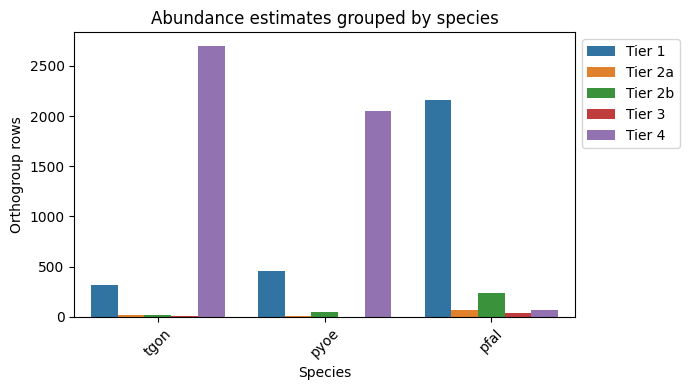

In [9]:
#@title Tier composition per species
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Species', hue='Tier',
              hue_order=['Tier 1', 'Tier 2a', 'Tier 2b', 'Tier 3', 'Tier 4'])
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.title('Abundance estimates grouped by species')
plt.xlabel('Species'); plt.ylabel('Orthogroup rows')
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

In [10]:
def estimate(row):
    # Returns (log10 ppm, spread in log10 units) for one orthogroup row.
    vals = row.vals
    if not vals or row.Tier == 'Tier 4':
        return np.nan, np.nan

    if ALREADY_LOG:
        logs = vals
        lin  = [10 ** v for v in vals]
    else:
        pos = [v for v in vals if v > 0]
        if not pos:
            return np.nan, np.nan
        lin  = pos
        logs = [math.log10(v) for v in pos]

    n = max(int(row.n_ccay), 1)
    if   row.Tier == 'Tier 1':  est = lin[0]
    elif row.Tier == 'Tier 2a': est = float(np.median(lin))
    elif row.Tier == 'Tier 2b': est = lin[0] / n
    elif row.Tier == 'Tier 3':  est = sum(lin) / n
    else:                       return np.nan, np.nan

    spread = float(np.std(logs, ddof=1)) if len(logs) > 1 else 0.0
    return math.log10(est), spread


df[['log10_ppm', 'log10_sd']] = df.apply(estimate, axis=1, result_type='expand')

bad = df[df.Tier.isin(USABLE) & df.log10_ppm.isna()]
assert len(bad) == 0, f'{len(bad)} usable tiers with no estimate:\n{bad.head()}'
print(df.groupby('Tier').log10_ppm.describe()[['count', 'mean', 'min', 'max']])

          count      mean       min       max
Tier                                         
Tier 1   2929.0  1.323343 -1.638272  4.204093
Tier 2a    81.0  1.039573 -1.677781  3.642267
Tier 2b   301.0  1.180991 -2.246672  4.138760
Tier 3     37.0  1.248165 -0.756962  3.764923
Tier 4      0.0       NaN       NaN       NaN


`log10_sd` is the spread between the orthologs inside one group. A large spread means the orthologs disagree with each other, so the estimate is weak even when its tier is good. Carry it through and use it to break ties later.

In [11]:
#@title Explode to one row per CCay protein, then pivot the species into columns
long = df.explode('ccay_ids').rename(columns={'ccay_ids': 'ccay_id'})
long = long[long.ccay_id.notna()]

dups = long.duplicated(['ccay_id', 'Species']).sum()
assert dups == 0, f'{dups} duplicate (ccay_id, Species) pairs. Check the orthogroup assignment.'

wide = long.pivot_table(
    index='ccay_id',
    columns='Species',
    values=['log10_ppm', 'log10_sd', 'coverage', 'Tier', 'Orthogroup'],
    aggfunc='first',
)
wide.columns = [f'{metric}_{sp}' for metric, sp in wide.columns]
wide = wide.reset_index()
assert len(wide) == long.ccay_id.nunique()
print(wide.shape)

(3275, 16)


In [12]:
def pick(r):
    # Take the estimate from the closest relative that produced a usable tier.
    for sp in PREF:
        if r.get(f'Tier_{sp}') in USABLE and pd.notna(r.get(f'log10_ppm_{sp}')):
            return pd.Series([r[f'log10_ppm_{sp}'], r[f'log10_sd_{sp}'],
                              r[f'Tier_{sp}'], sp])
    return pd.Series([np.nan, np.nan, 'Tier 4', None])


wide[['log10_ppm', 'log10_sd', 'Tier', 'source_species']] = wide.apply(
    pick, axis=1, result_type='expand')

print(pd.crosstab(wide.source_species.fillna('none'), wide.Tier), '\n')
print(wide.log10_sd.describe())

wide.drop(columns=[c for c in wide.columns if c.startswith('Orthogroup_')]) \
    .to_csv(PROJECT / '05_abundance_per_protein.tsv', sep='\t', index=False)
wide.head()

Tier            Tier 1  Tier 2a  Tier 2b  Tier 3  Tier 4
source_species                                          
none                 0        0        0       0     316
pfal              1531       48      431      96       0
pyoe               388        2      101       3       0
tgon               313       12       30       4       0 

count    2959.000000
mean        0.026670
std         0.151934
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.579599
Name: log10_sd, dtype: float64


,ccay_id,Orthogroup_pfal,Orthogroup_pyoe,Orthogroup_tgon,Tier_pfal,Tier_pyoe,Tier_tgon,coverage_pfal,coverage_pyoe,coverage_tgon,log10_ppm_pfal,log10_ppm_pyoe,log10_ppm_tgon,log10_sd_pfal,log10_sd_pyoe,log10_sd_tgon,log10_ppm,log10_sd,Tier,source_species
0,XP_022586359.2,OG0000119,OG0000119,OG0000119,Tier 2b,Tier 4,Tier 4,1.0,0.0,0.0,1.298853,NaN,NaN,0.0,NaN,NaN,1.298853,0.0,Tier 2b,pfal
1,XP_022586363.2,NaN,NaN,OG0002751,NaN,NaN,Tier 4,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Tier 4,None
2,XP_022586398.1,OG0000816,OG0000816,OG0000816,Tier 1,Tier 4,Tier 4,1.0,0.0,0.0,2.881385,NaN,NaN,0.0,NaN,NaN,2.881385,0.0,Tier 1,pfal
3,XP_022586434.2,OG0000371,OG0000371,OG0000371,Tier 2b,Tier 4,Tier 2b,1.0,0.0,1.0,1.205475,NaN,-1.177178,0.0,NaN,0.0,-1.177178,0.0,Tier 2b,tgon
4,XP_022586436.2,NaN,NaN,OG0002752,NaN,NaN,Tier 4,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Tier 4,None


---

## **2. Load the other metrics and bridge the identifiers.**

Since the upstream notebooks key output differently, we'll rebuild the same bridge used in CCB04 so all four tables can be joined on the protein accession.

```
  lift_per_gene.csv        DeepLoc CSV         04_diversity.csv
     gene-LOC...      ->     XP_......    <-      XM_......
                  (reference GFF supplies both links)
```


In [13]:
ref_gff = gff3p.parse_gff3(str(REF_GFF), parse_attributes=True, verbose=False)

def extract_dbxref(val, key):
    if not isinstance(val, str):
        return None
    for ref in val.split(','):
        if ref.startswith(key):
            return ref.split(':')[1]
    return None

ref_gff['GeneID']  = ref_gff['Dbxref'].apply(lambda v: extract_dbxref(v, 'GeneID'))
ref_gff['GenBank'] = ref_gff['Dbxref'].apply(lambda v: extract_dbxref(v, 'GenBank'))

loc_xp = {}
for _, group in ref_gff.groupby('GeneID'):
    ids = group.Name.values
    loc = [x for x in ids if isinstance(x, str) and x.startswith('LOC')]
    xp  = {x for x in ids if isinstance(x, str) and x.startswith('XP')}
    if loc and xp:
        loc_xp[f'gene-{loc[0]}'] = xp.pop()

loc_xm = {}
for _, group in ref_gff.groupby('GeneID'):
    group = group.drop_duplicates(subset=['GenBank'])
    group = group[group['gbkey'] == 'CDS']
    for row in group.itertuples():
        if isinstance(row.GenBank, str) and isinstance(row.Parent, str):
            loc_xm[row.GenBank] = row.Parent.split('-')[1]

print(f'{len(loc_xp)} gene -> protein | {len(loc_xm)} protein -> transcript')

/usr/local/lib/python3.13/dist-packages/gff3_parser/parser.py:36: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = pd.DataFrame(data).replace('.', np.nan)


5793 gene -> protein | 5793 protein -> transcript


In [14]:
localizations = pd.read_csv(LOC_CSV)
per_gene      = pd.read_csv(PER_GENE)
diversity     = pd.read_csv(DIVERSITY)

per_gene['Protein_ID']    = per_gene['gene_id'].map(loc_xp)
per_gene['Transcript_ID'] = per_gene['Protein_ID'].map(loc_xm)

print('localization :', localizations.shape)
print('per-gene QC  :', per_gene.shape)
print('diversity    :', diversity.shape)
diversity.head()

localization : (5793, 18)
per-gene QC  : (5940, 10)
diversity    : (63, 11)


,Transcript_ID,transcript_raw,n_aligned,N_sites,S_sites,N_diffs,S_diffs,piN,piS,piN_piS,diversity_class
0,XM_022730665.1,rna-XM_022730665.1,36,1410.500000,404.500000,0.0,0.268254,0.0,0.000663,0.0,synonymous_only
1,XM_022731842.2,rna-XM_022731842.2,37,0.000000,0.000000,0.0,0.000000,NaN,NaN,NaN,invariant
2,XM_022731922.2,rna-XM_022731922.2,36,956.000000,295.000000,0.0,0.000000,0.0,0.000000,NaN,invariant
3,XM_022732228.1,rna-XM_022732228.1,36,960.000000,288.000000,0.0,0.000000,0.0,0.000000,NaN,invariant
4,XM_022734555.2,rna-XM_022734555.2,35,1575.333333,458.666667,0.0,0.000000,0.0,0.000000,NaN,invariant


---

## **3. Assemble one table.**

Join with left merges onto the localization table, which covers the whole predicted proteome. We are keeping every protein at this stage, including ones with missing metrics.


In [15]:
metrics = localizations.copy()

metrics = metrics.merge(
    wide[['ccay_id', 'log10_ppm', 'log10_sd', 'Tier', 'source_species']],
    left_on='Protein_ID', right_on='ccay_id', how='left').drop(columns='ccay_id')

metrics = metrics.merge(
    per_gene[['gene_id', 'Protein_ID', 'Transcript_ID', 'usable_rate']],
    on='Protein_ID', how='left')

metrics = metrics.merge(
    diversity[['Transcript_ID', 'piN', 'piS', 'piN_piS',
               'diversity_class', 'n_aligned']],
    on='Transcript_ID', how='left')

print('proteins:', len(metrics))
metrics.head()

proteins: 5793


,Protein_ID,Localizations,Signals,Membrane types,Cytoplasm,Nucleus,Extracellular,Cell membrane,Mitochondrion,Plastid,Endoplasmic reticulum,Lysosome/Vacuole,Golgi apparatus,Peroxisome,Peripheral,Transmembrane,Lipid anchor,Soluble,log10_ppm,log10_sd,Tier,source_species,gene_id,Transcript_ID,usable_rate,piN,piS,piN_piS,diversity_class,n_aligned
0,XP_022586349.2,Endoplasmic reticulum,Signal peptide|Transmembrane domain,Transmembrane,0.1282,0.1820,0.0449,0.3204,0.1403,0.0166,0.8768,0.3592,0.4063,0.0034,0.0602,0.9968,0.0733,0.0925,NaN,NaN,NaN,NaN,gene-LOC34623630,XM_022736747.2,0.837209,NaN,NaN,NaN,NaN,NaN
1,XP_022586352.2,Cytoplasm,Nuclear localization signal,Soluble,0.6825,0.5030,0.0695,0.2695,0.1132,0.0119,0.0488,0.1567,0.2283,0.0216,0.5857,0.0544,0.0791,0.7674,NaN,NaN,NaN,NaN,gene-LOC34623633,XM_022736750.2,0.976744,NaN,NaN,NaN,NaN,NaN
2,XP_022586359.2,Cytoplasm,Nuclear export signal,Soluble,0.5634,0.4525,0.0260,0.2451,0.3105,0.0432,0.1402,0.3217,0.3660,0.0141,0.6064,0.0998,0.0761,0.6501,1.298853,0.0,Tier 2b,pfal,gene-LOC34621508,XM_022734717.2,0.953488,NaN,NaN,NaN,NaN,NaN
3,XP_022586363.2,Endoplasmic reticulum,Signal peptide,Soluble,0.1384,0.0863,0.5286,0.1683,0.1092,0.0751,0.5906,0.5054,0.4678,0.0087,0.4487,0.1352,0.0294,0.6851,NaN,NaN,Tier 4,None,gene-LOC34621512,XM_022734721.2,0.976744,NaN,NaN,NaN,NaN,NaN
4,XP_022586398.1,Cytoplasm|Nucleus,NaN,Soluble,0.5415,0.5831,0.2129,0.0653,0.2987,0.0305,0.1886,0.0914,0.2443,0.0206,0.5487,0.0857,0.1642,0.7805,2.881385,0.0,Tier 1,pfal,gene-LOC34620001,XM_022733273.1,0.930233,NaN,NaN,NaN,NaN,NaN


                          proteins
localization (DeepLoc)        5793
abundance (usable tier)       2959
gene model QC (liftover)      5793
diversity (SNPGenie)            62
all four                        37


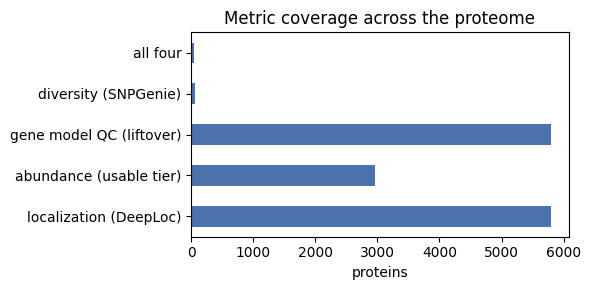

In [16]:
#@title How many proteins carry each metric?
coverage_report = pd.Series({
    'localization (DeepLoc)': metrics.Extracellular.notna().sum(),
    'abundance (usable tier)': metrics.Tier.isin(USABLE).sum(),
    'gene model QC (liftover)': metrics.usable_rate.notna().sum(),
    'diversity (SNPGenie)': metrics.piN.notna().sum(),
    'all four': (metrics.Extracellular.notna() & metrics.Tier.isin(USABLE) &
                 metrics.usable_rate.notna() & metrics.piN.notna()).sum(),
}).rename('proteins')

print(coverage_report.to_frame())

plt.figure(figsize=(6, 3))
coverage_report.plot(kind='barh', color='#4C72B0')
plt.xlabel('proteins'); plt.title('Metric coverage across the proteome')
plt.tight_layout(); plt.show()

In [17]:
metrics.to_csv(PROJECT / '05_metrics.tsv', sep='\t', index=False)
print('wrote', PROJECT / '05_metrics.tsv')

wrote /content/drive/MyDrive/CCayProject/05_metrics.tsv


---

## **4. Threshold each axis, then intersect.**

| Axis | Filter | Why |
| :-- | :-- | :-- |
| Exposure | `Extracellular >= 0.70` | The antibody has to reach the epitope on an intact oocyst. |
| Gene model | `usable_rate >= 0.90` | A model that does not lift over cleanly is probably wrong in the reference too. |
| Abundance | `log10_ppm >= 1.0` and a usable tier | Under about 10 ppm there is not enough antigen per oocyst for a visible line. |
| Invariance | `piN_piS < 1`, **or** an undefined ratio with `piN <= 0.01` | The epitope must be the same in every isolate on the lettuce. |
| Evidence depth | `n_aligned >= 20` | A diversity value from a few assemblies is not reliable. |

### **Handling the undefined ratio**

CCB04 classed each gene. Genes with `piS = 0` have no πN/πS, and a naive `piN_piS < 1` test drops them. For `invariant` and `synonymous_only` genes that is backwards: their protein sequence does not change at all, which is the ideal case. The rule below passes them explicitly and judges `no_synonymous` genes on πN alone.


In [18]:
f_exposed   = metrics.Extracellular >= EXTRACELLULAR_MIN
f_genemodel = metrics.usable_rate      >= USABLE_RATE_MIN
f_abundant  = (metrics.log10_ppm >= LOG10_PPM_MIN) & metrics.Tier.isin(USABLE)
f_depth     = metrics.n_aligned >= MIN_ALIGNED

ratio_ok     = metrics.piN_piS < PIN_PIS_MAX
no_change    = metrics.diversity_class.isin(['invariant', 'synonymous_only'])
undefined_ok = (metrics.diversity_class == 'no_synonymous') & (metrics.piN <= PIN_MAX)
f_invariant  = (ratio_ok | no_change | undefined_ok).fillna(False)

filters = pd.DataFrame({
    'exposed':    f_exposed.fillna(False),
    'gene_model': f_genemodel.fillna(False),
    'abundant':   f_abundant.fillna(False),
    'invariant':  f_invariant,
    'depth':      f_depth.fillna(False),
})

print(filters.sum().rename('proteins passing').to_frame())
print('\nintersection of all five:', filters.all(axis=1).sum())

            proteins passing
exposed                  246
gene_model              4313
abundant                1543
invariant                 61
depth                     63

intersection of all five: 25


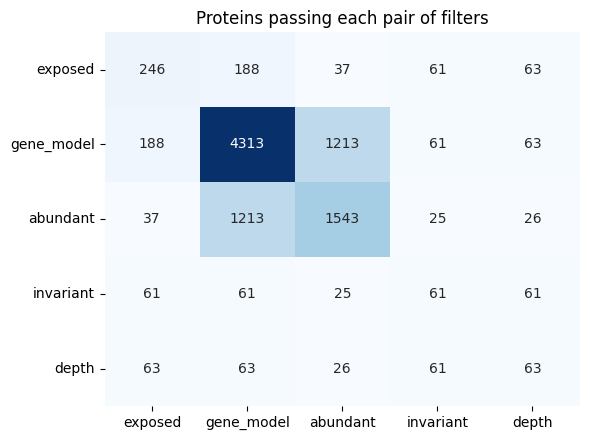

In [19]:
#@title How much does each filter remove on its own?
pair = pd.DataFrame(
    [[(filters[a] & filters[b]).sum() for b in filters.columns] for a in filters.columns],
    index=filters.columns, columns=filters.columns)

plt.figure(figsize=(6, 4.5))
sns.heatmap(pair, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Proteins passing each pair of filters')
plt.tight_layout(); plt.show()

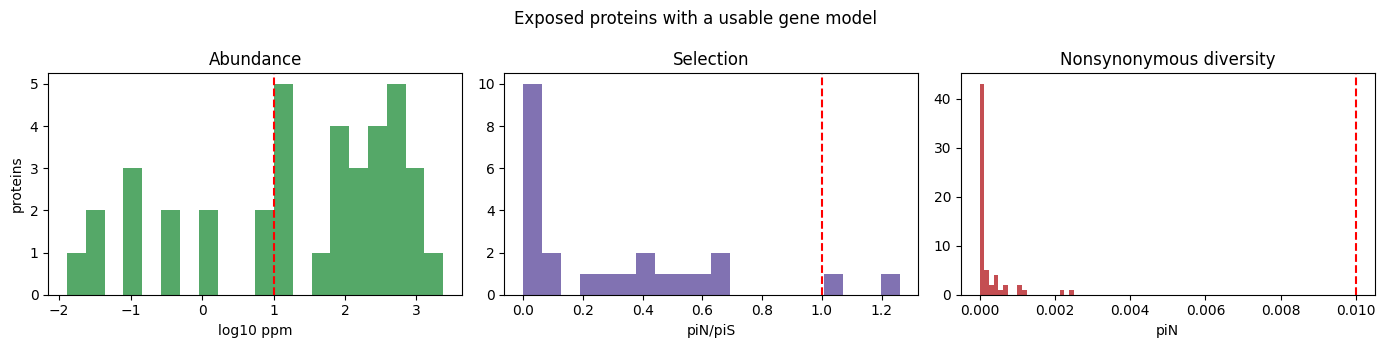

In [20]:
#@title Distributions with the thresholds drawn on
measured = metrics[filters.exposed & filters.gene_model]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))

ax[0].hist(measured.log10_ppm.dropna(), bins=20, color='#55A868')
ax[0].axvline(LOG10_PPM_MIN, ls='--', c='r')
ax[0].set_xlabel('log10 ppm'); ax[0].set_ylabel('proteins'); ax[0].set_title('Abundance')

ax[1].hist(measured.piN_piS.dropna(), bins=20, color='#8172B2')
ax[1].axvline(PIN_PIS_MAX, ls='--', c='r')
ax[1].set_xlabel('piN/piS'); ax[1].set_title('Selection')

ax[2].hist(measured.piN.dropna(), bins=20, color='#C44E52')
ax[2].axvline(PIN_MAX, ls='--', c='r')
ax[2].set_xlabel('piN'); ax[2].set_title('Nonsynonymous diversity')

fig.suptitle('Exposed proteins with a usable gene model')
plt.tight_layout(); plt.show()

In [21]:
#@title The waterfall: what is lost at each step
order = ['exposed', 'gene_model', 'depth', 'invariant', 'abundant']
running = pd.Series(True, index=metrics.index)
rows = [{'step': 'all predicted proteins', 'remaining': len(metrics), 'lost': 0}]

for f in order:
    before = running.sum()
    running = running & filters[f]
    rows.append({'step': f'+ {f}', 'remaining': int(running.sum()),
                 'lost': int(before - running.sum())})

waterfall = pd.DataFrame(rows)
print(waterfall.to_string(index=False))

                  step  remaining  lost
all predicted proteins       5793     0
             + exposed        246  5547
          + gene_model        188    58
               + depth         63   125
           + invariant         61     2
            + abundant         25    36


---

## **5. Rank the survivors.**

The score below is the mean of two percentile ranks: abundance (higher is better) and πN (lower is better). Both are first converted to percentiles. This is a heuristic for prioritization, not a statistical model. Read the component columns next to it, and prefer a candidate with a low `log10_sd` when two scores are close.


In [22]:
shortlist = metrics[filters.all(axis=1)].copy()

shortlist['rank_abundance'] = shortlist.log10_ppm.rank(pct=True)
shortlist['rank_invariance'] = 1 - shortlist.piN.rank(pct=True, na_option='bottom')
shortlist['score'] = shortlist[['rank_abundance', 'rank_invariance']].mean(axis=1)

shortlist = shortlist.sort_values('score', ascending=False).reset_index(drop=True)
shortlist.insert(0, 'rank', shortlist.index + 1)

cols = ['rank', 'gene_id', 'Protein_ID', 'Transcript_ID', 'Localizations',
        'Extracellular', 'usable_rate',
        'log10_ppm', 'log10_sd', 'Tier', 'source_species',
        'piN', 'piS', 'piN_piS', 'diversity_class', 'n_aligned',
        'rank_abundance', 'rank_invariance', 'score']
cols = [c for c in cols if c in shortlist.columns]

shortlist[cols].to_csv(PROJECT / '05_shortlist.tsv', sep='\t', index=False)
print(f'{len(shortlist)} candidates written to {PROJECT / "05_shortlist.tsv"}\n')
shortlist[cols].head(25)

25 candidates written to /content/drive/MyDrive/CCayProject/05_shortlist.tsv



,rank,gene_id,Protein_ID,Transcript_ID,Localizations,Extracellular,usable_rate,log10_ppm,log10_sd,Tier,source_species,piN,piS,piN_piS,diversity_class,n_aligned,rank_abundance,rank_invariance,score
0,1,gene-LOC34617317,XP_026192732.1,XM_026336947.1,Extracellular,0.7565,0.976744,3.375115,0.000000,Tier 1,pfal,0.000000,0.000201,0.000000,synonymous_only,35.0,1.00,0.74,0.87
1,2,gene-LOC113146615,XP_026190325.1,XM_026334540.1,Extracellular,0.8874,1.000000,3.032820,0.000000,Tier 2b,pfal,0.000000,0.000000,NaN,invariant,36.0,0.94,0.74,0.84
2,3,gene-LOC34622212,XP_026190815.1,XM_026335030.1,Extracellular,0.9321,0.976744,3.032820,0.000000,Tier 2b,pfal,0.000000,0.001052,0.000000,synonymous_only,35.0,0.94,0.74,0.84
3,4,gene-LOC113147332,XP_026193328.1,XM_026337543.1,Extracellular,0.7515,0.976744,2.940018,0.822344,Tier 3,pyoe,0.000000,0.000000,NaN,invariant,35.0,0.88,0.74,0.81
4,5,gene-LOC34619074,XP_026193026.1,XM_026337241.1,Extracellular,0.9264,0.976744,2.723729,0.000000,Tier 2b,pyoe,0.000000,0.000000,NaN,invariant,35.0,0.72,0.74,0.73
5,6,gene-LOC34622326,XP_026193915.1,XM_026338130.1,Extracellular|Endoplasmic reticulum,0.7014,1.000000,2.666518,0.000000,Tier 1,pfal,0.000000,0.000000,NaN,invariant,36.0,0.68,0.74,0.71
6,7,gene-LOC34618447,XP_026190084.1,XM_026334299.1,Extracellular,0.8236,1.000000,2.375664,0.000000,Tier 2b,pfal,0.000000,0.000000,NaN,invariant,37.0,0.54,0.74,0.64
7,8,gene-LOC34618352,XP_026193807.1,XM_026338022.1,Extracellular,0.8559,1.000000,2.375664,0.000000,Tier 2b,pfal,0.000000,0.000000,NaN,invariant,37.0,0.54,0.74,0.64
8,9,gene-LOC34621493,XP_022587513.1,XM_022734702.1,Extracellular,0.7526,1.000000,2.281033,0.000000,Tier 1,pyoe,0.000000,0.000000,NaN,invariant,36.0,0.44,0.74,0.59
9,10,gene-LOC34617422,XP_026191628.1,XM_026335843.1,Extracellular,0.8093,0.976744,2.847573,0.000000,Tier 1,pfal,0.000206,0.000000,NaN,no_synonymous,35.0,0.84,0.28,0.56


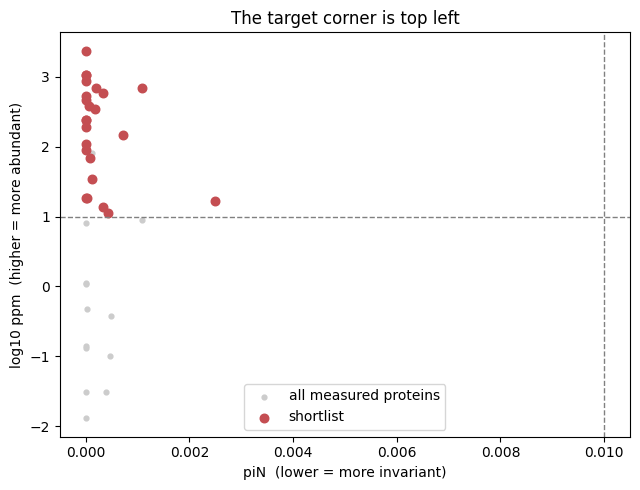

In [23]:
#@title Where the shortlist sits against the rest of the proteome
plt.figure(figsize=(6.5, 5))
bg = metrics[metrics.log10_ppm.notna() & metrics.piN.notna()]
plt.scatter(bg.piN, bg.log10_ppm, s=12, c='#CCCCCC', label='all measured proteins')
plt.scatter(shortlist.piN, shortlist.log10_ppm, s=38, c='#C44E52', label='shortlist')
plt.axhline(LOG10_PPM_MIN, ls='--', c='grey', lw=1)
plt.axvline(PIN_MAX, ls='--', c='grey', lw=1)
plt.xlabel('piN  (lower = more invariant)')
plt.ylabel('log10 ppm  (higher = more abundant)')
plt.title('The target corner is top left')
plt.legend(); plt.tight_layout(); plt.show()

In [24]:
#@title Composition of the shortlist
print(shortlist.diversity_class.value_counts().rename('candidates').to_frame(), '\n')
print(shortlist.Tier.value_counts().rename('candidates').to_frame(), '\n')
print(shortlist.source_species.value_counts().rename('candidates').to_frame(), '\n')
print(shortlist[['Extracellular', 'log10_ppm', 'piN', 'n_aligned']].describe())

                 candidates
diversity_class            
invariant                 9
no_synonymous             7
ratio                     5
synonymous_only           4 

         candidates
Tier               
Tier 1           13
Tier 2b          10
Tier 3            1
Tier 2a           1 

                candidates
source_species            
pfal                    17
pyoe                     6
tgon                     2 

       Extracellular  log10_ppm        piN  n_aligned
count      25.000000  25.000000  24.000000  25.000000
mean        0.818844   2.246703   0.000253  35.960000
std         0.073179   0.678837   0.000548   0.840635
min         0.701400   1.054996   0.000000  35.000000
25%         0.752600   1.841985   0.000000  35.000000
50%         0.809300   2.375664   0.000011  36.000000
75%         0.887400   2.775974   0.000237  37.000000
max         0.932100   3.375115   0.002499  37.000000


---

## **6. Read the result with care.**

Before this list goes to structure prediction and binder design, note what it cannot tell you:

1. **Abundance is borrowed.** Every `log10_ppm` comes from *T. gondii*, *P. yoelii* or *P. falciparum*, not from CCay, and not from the oocyst stage that a produce swab actually collects. A protein abundant in a *T. gondii* tachyzoite may be absent from a sporulated CCay oocyst. This is the weakest axis in the whole pipeline.
2. **Exposure is predicted.** DeepLoc gives a localization probability, not surface accessibility on an intact oocyst wall. The CCay oocyst wall may hide a correctly-predicted extracellular protein.
3. **Diversity is bounded by the sample.** The 44 assemblies skew toward USA and Nepal isolates. A gene that looks invariant here may vary in a lineage that was never sequenced. The πN values are a lower bound on true diversity.
4. **The reference annotation is ab initio.** Gnomon gene models are predictions. A wrong model produces a real-looking πN on a gene that does not exist as drawn.

The honest reading: this shortlist ranks **hypotheses worth testing**, in a sensible order. Each candidate needs its own empirical check.

### **Next**

`05_shortlist.tsv` goes to **CCB06**, which maps the proteins to UniProt, pulls the AlphaFold DB models and the pLDDT, and starts structure-level triage of epitope regions.
